# Notebook 3 — Temperature acquisition with a thermocouple and the Keithley 2000

*Python for Instrumentation and Laboratory Experiments — Pr. T. Angot*

**Subject:** retrieve the thermocouple voltage every 1 s and store time, voltage and temperature in arrays for at least 900 s. Convert the voltage to temperature with the ITS-90 polynomial of a type K thermocouple. Plot the data and save them to a file.
This program will be used in Experimental Physics to record the **cooling of liquid tin** and observe its solidification (and supercooling, *surfusion*).

**Status of the measurement.** During our session the Keithley was connected to the computer, but **no thermocouple was connected to its input** (see notebook 2: the reading was a meaningless floating value). So the 900 s measurement could not be done. The acquisition program below is complete and ready for the lab. To check that it works, I ran it on a **simulated** Keithley (section 5): those curves are generated by a model, they are **not measured data**.

## 1. Physics

**Thermocouple.** Two different metals (for type K: chromel and alumel) are joined at the measuring point. Because of the Seebeck effect, a voltage appears that depends on the temperature difference between this *hot junction* and the *reference (cold) junction*, the place where the thermocouple wires meet the copper terminals of the voltmeter. For type K the sensitivity is about 41 µV/°C, so we use the 100 mV range of the Keithley.

The tables and polynomials (ITS-90) give the voltage $E(T)$ for a reference junction at 0 °C. If the reference is at room temperature $T_{ref}$ (no ice bath), we must add back the voltage of the reference before converting (**cold junction compensation**):

$$E(T) = V_{measured} + E(T_{ref}) \quad\Longrightarrow\quad T = E^{-1}\!\left(V_{measured} + E(T_{ref})\right)$$

Simply adding $T_{ref}$ to the temperature is only an approximation, because $E(T)$ is not exactly linear.

**Tin.** Pure tin melts and solidifies at $T_m = 231.93$ °C. When liquid tin cools down:
1. the temperature decreases (Newton's law of cooling, roughly exponential),
2. it often goes a few degrees **below** $T_m$ while staying liquid: this is **supercooling** (*surfusion*), a metastable state, because the first solid crystals need a nucleation site to appear,
3. when solidification starts, the latent heat released makes the temperature jump back up to $T_m$ (*recalescence*),
4. the temperature stays constant at $T_m$ (**plateau**) as long as liquid and solid coexist,
5. once everything is solid, the temperature decreases again.

The plateau gives a reference temperature: it can be used to check the calibration of the whole chain (thermocouple + reference junction + conversion).

## 2. Libraries

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import serial

## 3. Conversion voltage ↔ temperature (type K, ITS-90)

Coefficients from the NIST ITS-90 tables (https://aviatechno.net/thermo/table_its90.php?type=K).

- **Temperature → voltage** (0 to 1372 °C): $E = \sum_{i=0}^{9} c_i T^i + a_0\, e^{a_1 (T - a_2)^2}$, with $E$ in mV. Used for the cold junction compensation (and for the simulation).
- **Voltage → temperature**: $T = d_0 + d_1 E + d_2 E^2 + \dots$, with a different set of coefficients for each range:

| Voltage range (mV) | −5.891 → 0 | 0 → 20.644 | 20.644 → 54.886 |
|---|---|---|---|
| Temperature (°C) | −200 → 0 | 0 → 500 | 500 → 1372 |

In [2]:
# voltage (mV) -> temperature (°C), coefficients d0..dn of each range
d_neg  = [0, 2.5173462E+1, -1.1662878E+0, -1.0833638E+0, -8.9773540E-1,
          -3.7342377E-1, -8.6632643E-2, -1.0450598E-2, -5.1920577E-4]                   # -5.891 to 0 mV
d_mid  = [0, 2.508355E+1, 7.860106E-2, -2.503131E-1, 8.315270E-2,
          -1.228034E-2, 9.804036E-4, -4.413030E-5, 1.057734E-6, -1.052755E-8]           # 0 to 20.644 mV
d_high = [-1.318058E+2, 4.830222E+1, -1.646031E+0, 5.464731E-2,
          -9.650715E-4, 8.802193E-6, -3.110810E-8]                                        # 20.644 to 54.886 mV

# temperature (°C) -> voltage (mV), 0 to 1372 °C
c_pos = [-1.76004136860E-2, 3.89212049750E-2, 1.85587700320E-5, -9.94575928740E-8,
         3.18409457190E-10, -5.60728448890E-13, 5.60750590590E-16, -3.20207200030E-19,
         9.71511471520E-23, -1.21047212750E-26]
a0, a1, a2 = 1.185976E-1, -1.183432E-4, 1.269686E+2

def temp_to_mV(T):
    # np.polyval wants the highest power first, hence [::-1]
    return np.polyval(c_pos[::-1], T) + a0*np.exp(a1*(T - a2)**2)

def volt_to_temp(V, T_ref=0.0):
    # V: measured voltage in volts, T_ref: temperature of the reference junction in °C
    x = V*1000 + temp_to_mV(T_ref)   # mV, cold junction compensation
    if x < -5.891 or x > 54.886:
        return np.nan                 # outside the range of the polynomials
    if x < 0:
        d = d_neg
    elif x <= 20.644:
        d = d_mid
    else:
        d = d_high
    return float(np.polyval(d[::-1], x))

Check against the reference table (`Type-K-Thermocouple-Reference-Table.pdf`), and check that the two polynomials are inverse of each other:

In [3]:
for T in [0, 100, 231.93, 500, 1000]:
    print(f"{T:8.2f} °C  ->  {temp_to_mV(T):7.3f} mV  ->  {volt_to_temp(temp_to_mV(T)/1000):8.2f} °C")
# table values: 100 °C = 4.096 mV, 500 °C = 20.644 mV, 1000 °C = 41.276 mV

T_test = np.linspace(0, 1300, 2601)
err = [volt_to_temp(temp_to_mV(T)/1000) - T for T in T_test]
print("max round-trip error between 0 and 1300 °C: %.3f °C" % np.max(np.abs(err)))

# cold junction: 9.000 mV measured with the terminals at 22 °C
print("9.000 mV, reference at 0 °C : %.2f °C" % volt_to_temp(9.000e-3, 0))
print("9.000 mV, reference at 22 °C: %.2f °C" % volt_to_temp(9.000e-3, 22))

    0.00 °C  ->    0.000 mV  ->      0.00 °C
  100.00 °C  ->    4.096 mV  ->     99.97 °C
  231.93 °C  ->    9.421 mV  ->    231.91 °C
  500.00 °C  ->   20.644 mV  ->    499.95 °C
 1000.00 °C  ->   41.276 mV  ->    999.98 °C
max round-trip error between 0 and 1300 °C: 0.047 °C
9.000 mV, reference at 0 °C : 221.47 °C
9.000 mV, reference at 22 °C: 243.24 °C


The polynomials reproduce the table, and the round-trip error stays below 0.06 °C, which is the accuracy given by NIST for the inverse polynomials. Forgetting the cold junction shifts every temperature by about 22 °C.

## 4. Acquisition program

- The meter is configured first (DC volts, 100 mV range, NPLC 5), whatever state it was left in.
- A reading is requested every `dt` seconds. The waiting time is computed from the start time `t0 + k*dt`, so that small delays do not accumulate over 900 points.
- A missing or unreadable reply only skips one point instead of stopping the whole measurement. An overflow (`+9.9E37`, sent when the input is out of range) is stored as `nan`.
- The curve is redrawn every 10 points (`clear_output` + new plot) to follow the experiment live.
- *Kernel → Interrupt* stops the measurement and keeps the data already taken.
- `clock` and `wait` are the functions used to read the time and to wait. By default they are the real ones (`time.time`, `time.sleep`). This only matters for the test in section 5.

In [4]:
def show_live(t_list, T_list):
    clear_output(wait=True)
    plt.figure(figsize=(8, 4))
    plt.plot(t_list, T_list, 'r.-')
    plt.xlabel("time (s)")
    plt.ylabel("temperature (°C)")
    plt.title(f"{len(t_list)} points, last T = {T_list[-1]:.2f} °C")
    plt.show()

def acquire(ser, duration=900, dt=1.0, T_ref=0.0, live=True, clock=time.time, wait=time.sleep):
    # configure the meter
    ser.write(b":SENS:FUNC 'VOLT:DC'\r")
    ser.write(b":SENS:VOLT:DC:RANG 0.1\r")
    ser.write(b":SENS:VOLT:DC:NPLC 5\r")
    wait(0.5)

    t_list, V_list, T_list = [], [], []
    t0 = clock()
    k = 0
    try:
        while k*dt <= duration:
            delay = t0 + k*dt - clock()
            if delay > 0:
                wait(delay)
            ser.reset_input_buffer()
            ser.write(b":READ?\r")
            raw = ser.readline().decode('ascii', errors='replace').strip()
            t = clock() - t0
            k += 1
            try:
                V = float(raw)
            except ValueError:
                print(f"t = {t:6.1f} s: bad or missing reply {raw!r}, point skipped")
                continue
            T = np.nan if abs(V) > 1e30 else volt_to_temp(V, T_ref)
            t_list.append(t); V_list.append(V); T_list.append(T)
            if live and len(t_list) % 10 == 0:
                show_live(t_list, T_list)
    except KeyboardInterrupt:
        print("Stopped by hand, the data already taken are kept.")
    return np.array(t_list), np.array(V_list), np.array(T_list)

def plot_data(t, V, T, title=""):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax1.plot(t, V*1000, 'b.-', ms=2, lw=0.5)
    ax1.set_ylabel("voltage (mV)")
    ax1.set_title(title)
    ax2.plot(t, T, 'r.-', ms=2, lw=0.5)
    ax2.set_ylabel("temperature (°C)")
    ax2.set_xlabel("time (s)")
    plt.show()

def save_data(filename, t, V, T):
    np.savetxt(filename, np.column_stack((t, V, T)), fmt="%.3f %.8e %.3f",
               header="time_s  voltage_V  temperature_C")
    print(len(t), "points saved to", filename)

### Real measurement (to run in the lab)

Before running: plug the thermocouple into the HI/LO input terminals, check the port name with the port list of notebook 2, and write the room temperature in `T_ref`. The voltage is saved too, so the temperature can be recomputed later with another `T_ref` if needed.

In [ ]:
serial_address = "COM3"   # port found in notebook 2
T_ref = 22.0              # °C, temperature of the Keithley terminals (room temperature)

with serial.Serial(serial_address, baudrate=9600, bytesize=8, parity='N', stopbits=1, timeout=2) as ser:
    t, V, T = acquire(ser, duration=900, dt=1.0, T_ref=T_ref)

plot_data(t, V, T, "Cooling of tin")
save_data("tin_thermocouple_data.txt", t, V, T)

## 5. Test of the program with a simulated Keithley

Since we have no measurement, I wrote a small class that behaves like the Keithley seen by `pyserial`: it accepts `write()` and answers `:READ?` through `readline()`. The voltage it returns comes from a **model** of a tin sample cooling down, using the type K table in reverse:

- liquid tin starting at 280 °C, Newton cooling towards a room at 22 °C (time constant 600 s),
- supercooling down to 5 °C below $T_m$, then fast recalescence to $T_m$ = 231.93 °C,
- a 300 s plateau, then cooling of the solid,
- the thermocouple measures relative to the terminals at 22 °C, with 1.5 µV of noise; one reply is lost on purpose at t ≈ 500 s.

A "virtual clock" replaces `time.time` / `time.sleep`, so the 900 s run takes a fraction of a second.

⚠️ **These are simulated data**, used only to test the program and to show the expected shape of the curve.

In [5]:
class VirtualClock:
    def __init__(self):
        self.now = 0.0
    def time(self):
        return self.now
    def sleep(self, s):
        self.now += s

T_m, T_room = 231.93, 22.0

def tin_model(t, T0=280.0, tau=600.0, undercool=5.0, plateau=300.0):
    t1 = tau*np.log((T0 - T_room)/(T_m - undercool - T_room))   # end of supercooling
    t2 = t1 + 5.0                                                # end of recalescence
    t3 = t2 + plateau                                            # end of solidification
    if t < t1:
        return T_room + (T0 - T_room)*np.exp(-t/tau)
    if t < t2:
        return T_m - undercool + undercool*(t - t1)/(t2 - t1)
    if t < t3:
        return T_m
    return T_room + (T_m - T_room)*np.exp(-(t - t3)/tau)

class FakeKeithley:
    def __init__(self, clock, noise=1.5e-6, seed=1):
        self.clock = clock
        self.rng = np.random.default_rng(seed)
        self.noise = noise
        self.reply = b""
        self.n_reads = 0
    def write(self, cmd):
        if cmd.startswith(b":READ?"):
            self.clock.sleep(0.1)                  # NPLC 5 = 100 ms of integration
            self.n_reads += 1
            T = tin_model(self.clock.time())
            V = (temp_to_mV(T) - temp_to_mV(T_room))/1000 + self.rng.normal(0, self.noise)
            self.reply = b"" if self.n_reads == 500 else f"{V:+.8E}\r\n".encode()
        return len(cmd)
    def readline(self):
        r, self.reply = self.reply, b""
        return r
    def reset_input_buffer(self):
        self.reply = b""

First run with `T_ref = 0`, as if we had forgotten the cold junction compensation:

t =  499.1 s: bad or missing reply '', point skipped
900 points, time step: mean 1.001 s, max 2.000 s


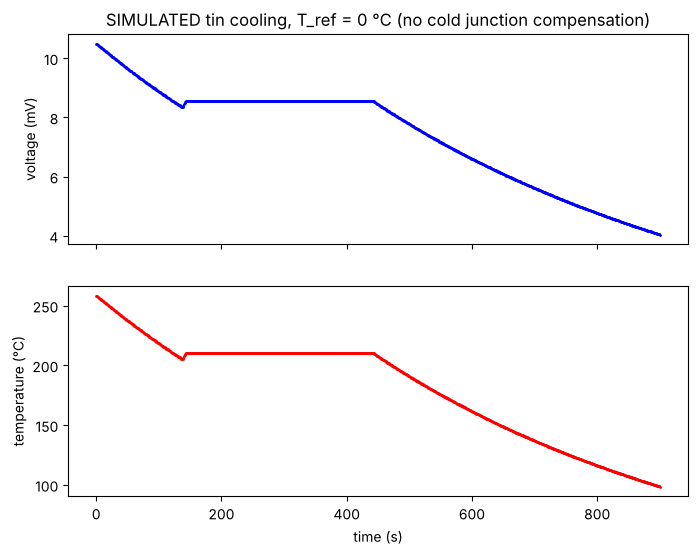

900 points saved to simulated_tin_data.txt


In [6]:
clock = VirtualClock()
fake = FakeKeithley(clock)
t_sim, V_sim, T_sim = acquire(fake, duration=900, dt=1.0, T_ref=0.0, live=False,
                              clock=clock.time, wait=clock.sleep)

print(len(t_sim), "points, time step: mean %.3f s, max %.3f s" % (np.mean(np.diff(t_sim)), np.max(np.diff(t_sim))))
plot_data(t_sim, V_sim, T_sim, "SIMULATED tin cooling, T_ref = 0 °C (no cold junction compensation)")
save_data("simulated_tin_data.txt", t_sim, V_sim, T_sim)

## 6. Analysis of the cooling curve

The plateau is found where the temperature (smoothed over 5 s) changes by less than 0.05 °C/s; the supercooling is the minimum of the temperature just before the plateau.
Since the plateau must be at 231.93 °C, it also gives the temperature of the reference junction: we look for the `T_ref` such that `volt_to_temp(V_plateau, T_ref)` = 231.93 °C.

In [7]:
def analyse_tin(t, V, T):
    ok = ~np.isnan(T)
    t, V, T = t[ok], V[ok], T[ok]
    T_smooth = np.convolve(T, np.ones(5)/5, mode='same')
    slope = np.gradient(T_smooth, t)
    flat = np.abs(slope) < 0.05
    flat[:3] = flat[-3:] = False          # edges of the smoothing are not reliable

    # longest group of consecutive "flat" points = plateau
    best, start = (0, 0), None
    for i, f in enumerate(np.append(flat, False)):
        if f and start is None:
            start = i
        elif not f and start is not None:
            if i - start > best[1] - best[0]:
                best = (start, i)
            start = None
    i1, i2 = best
    T_plateau = np.median(T[i1:i2])
    V_plateau = np.median(V[i1:i2])
    before = (t > t[i1] - 60) & (t < t[i1])
    T_min = np.min(T[before])
    return t[i1], t[i2-1], T_plateau, V_plateau, T_min

def find_T_ref(V_plateau, T_m=231.93):
    # E(T_m) = V_plateau + E(T_ref)  ->  E(T_ref) = E(T_m) - V_plateau
    return volt_to_temp((temp_to_mV(T_m) - V_plateau*1000)/1000, 0.0)

t_start, t_end, T_plat, V_plat, T_min = analyse_tin(t_sim, V_sim, T_sim)
print(f"plateau from {t_start:.0f} s to {t_end:.0f} s ({t_end - t_start:.0f} s), at {T_plat:.2f} °C")
print(f"supercooling: minimum {T_min:.2f} °C, i.e. {T_plat - T_min:.1f} °C below the plateau")
T_ref_found = find_T_ref(V_plat)
print(f"the plateau should be at 231.93 °C -> reference junction at {T_ref_found:.1f} °C")

plateau from 146 s to 441 s (295 s), at 210.05 °C
supercooling: minimum 205.18 °C, i.e. 4.9 °C below the plateau
the plateau should be at 231.93 °C -> reference junction at 22.0 °C


The voltages were saved, so there is no need to measure again: the temperatures are recomputed with the reference temperature found from the plateau.

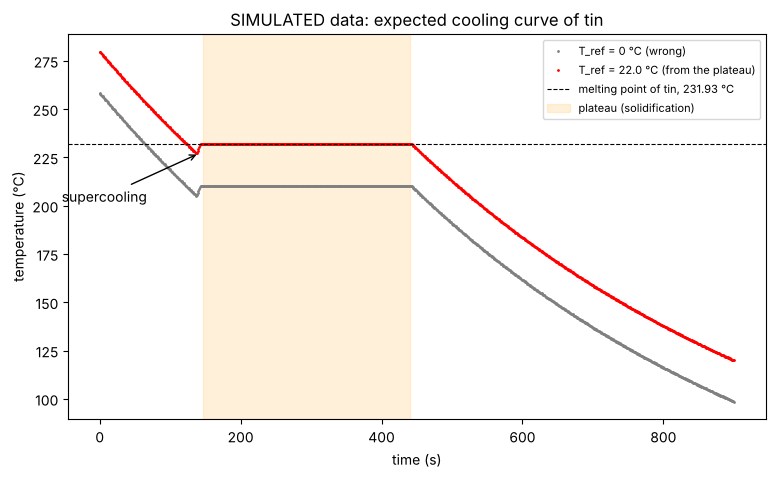

corrected plateau: 231.89 °C, supercooling: 4.8 °C


In [8]:
T_corr = np.array([volt_to_temp(v, T_ref_found) for v in V_sim])
t_start, t_end, T_plat, V_plat, T_min = analyse_tin(t_sim, V_sim, T_corr)

plt.figure(figsize=(9, 5))
plt.plot(t_sim, T_sim, '.', ms=2, color='gray', label='T_ref = 0 °C (wrong)')
plt.plot(t_sim, T_corr, 'r.', ms=2, label=f'T_ref = {T_ref_found:.1f} °C (from the plateau)')
plt.axhline(231.93, color='k', ls='--', lw=0.8, label='melting point of tin, 231.93 °C')
plt.axvspan(t_start, t_end, color='orange', alpha=0.15, label='plateau (solidification)')
plt.annotate('supercooling', xy=(t_start - 5, T_min), xytext=(t_start - 200, T_min - 25),
             arrowprops=dict(arrowstyle='->'))
plt.xlabel("time (s)")
plt.ylabel("temperature (°C)")
plt.title("SIMULATED data: expected cooling curve of tin")
plt.legend(fontsize=8)
plt.show()
print(f"corrected plateau: {T_plat:.2f} °C, supercooling: {T_plat - T_min:.1f} °C")

## 7. Conclusion

- The acquisition program reads the Keithley every second during 900 s, converts the voltage to temperature with the ITS-90 polynomials (including the cold junction compensation), shows the curve live and saves time, voltage and temperature to a text file.
- Tested on a simulated instrument, it keeps a regular 1 s step over 900 points, survives a lost reply, and the analysis finds the plateau, the supercooling and the temperature of the reference junction.
- Without compensation, the whole curve is shifted by about 22 °C (the plateau appears near 210 °C instead of 231.93 °C). The plateau of tin is a convenient calibration point to correct this.
- What remains is the real measurement: during our session no thermocouple was connected to the Keithley, so this will be done in the Experimental Physics lab with the cell *Real measurement* of section 4.